### Segment-Wise ISC Analysis

In [18]:
import numpy as np
import pandas as pd
import os
import utils.segment_isc_utils # Assuming your module works as before

### Set up Segments and Data

In [19]:
# --- CONFIGURATION ---
DATA_DIR = "../data/02_processed_combined_data"
CONDITIONS_FILE = "../data/sub_conditions.csv"
OUTPUT_DIR = "h2_segment_results"

if not os.path.exists(OUTPUT_DIR): os.makedirs(OUTPUT_DIR)

SEGMENTS = {
    'PC':  {1: (9, 54), 2: (55, 205), 3: (205, 243), 4: (243, 278), 5: (279, 319)},
    'PCM': {1: (9, 54), 2: (55, 205), 3: (205, 240), 4: (240, 278), 5: (279, 319)}
}

signals = ['Gaze_X', 'Gaze_Y', 'Pupil_Mean', 'Heart_Rate', 'GSR']
pc_subs  = utils.segment_isc_utils.get_subjects_by_condition(CONDITIONS_FILE, 'PC')
pcm_subs = utils.segment_isc_utils.get_subjects_by_condition(CONDITIONS_FILE, 'PCM')

### Define Helper Function and Run

In [20]:
# --- HELPER: PERMUTATION STATS ---
def calculate_permuted_stats(df_a, df_b, n_permutations=2000):
    """
    Returns: Mean r, Low_Err (distance), High_Err (distance)
    """
    n_a, n_b = df_a.shape[1], df_b.shape[1]
    k_a, k_b = int(n_a // 2), int(n_b // 2)
    
    if k_a < 1 or k_b < 1: return 0, 0, 0
    
    r_values = np.zeros(n_permutations)
    
    for i in range(n_permutations):
        idx_a = np.random.choice(n_a, k_a, replace=False)
        idx_b = np.random.choice(n_b, k_b, replace=False)
        g1 = df_a.iloc[:, idx_a].mean(axis=1)
        g2 = df_b.iloc[:, idx_b].mean(axis=1)
        r = np.corrcoef(g1, g2)[0, 1]
        r_values[i] = np.clip(r, -0.999999, 0.999999)

    # Fisher Z Statistics
    z_values = np.arctanh(r_values)
    mean_z = np.mean(z_values)
    ci_lower_z = np.percentile(z_values, 2.5)
    ci_upper_z = np.percentile(z_values, 97.5)
    
    mean_r = np.tanh(mean_z)
    # Return distances for error bars
    return mean_r, (mean_r - np.tanh(ci_lower_z)), (np.tanh(ci_upper_z) - mean_r)

# --- MAIN LOOP ---
master_results = []
print("Starting Segment-Wise Analysis...")

for signal in signals:
    print(f"  Processing {signal}...")
    try:
        # Load Data
        df_pc  = utils.segment_isc_utils.load_physio_data(DATA_DIR, pc_subs, signal_type=signal)
        df_pcm = utils.segment_isc_utils.load_physio_data(DATA_DIR, pcm_subs, signal_type=signal)
        
        # Trim to common length
        L = min(df_pc.shape[0], df_pcm.shape[0])
        df_pc, df_pcm = df_pc.iloc[:L], df_pcm.iloc[:L]
        
        # Extract Segments
        segs_pc  = utils.segment_isc_utils.extract_segments(df_pc, SEGMENTS['PC'], L)
        segs_pcm = utils.segment_isc_utils.extract_segments(df_pcm, SEGMENTS['PCM'], L)

        # 1. COMMON (Segs 1, 2, 5)
        d_com_pc  = pd.concat([segs_pc[1], segs_pc[2], segs_pc[5]], axis=0)
        d_com_pcm = pd.concat([segs_pcm[1], segs_pcm[2], segs_pcm[5]], axis=0)
        
        # 2. SCRAMBLED (Segs 3, 4 - Time Aligned / Content Mismatch)
        d_scr_pc  = pd.concat([segs_pc[3], segs_pc[4]], axis=0)
        d_scr_pcm = pd.concat([segs_pcm[3], segs_pcm[4]], axis=0)
        # Trim scrambled to min length
        min_s = min(d_scr_pc.shape[0], d_scr_pcm.shape[0])
        d_scr_pc, d_scr_pcm = d_scr_pc.iloc[:min_s], d_scr_pcm.iloc[:min_s]
        
        # 3. UNSCRAMBLED (Segs 3, 4 - Content Aligned / Time Mismatch)
        # PC: 3 then 4. PCM: 4 then 3. We reorder PCM to match PC.
        d_un_pc  = pd.concat([segs_pc[3], segs_pc[4]], axis=0)
        d_un_pcm = pd.concat([segs_pcm[4], segs_pcm[3]], axis=0) # SWAPPED
        # Trim unscrambled
        min_u = min(d_un_pc.shape[0], d_un_pcm.shape[0])
        d_un_pc, d_un_pcm = d_un_pc.iloc[:min_u], d_un_pcm.iloc[:min_u]
        
        # Calculate Stats
        tasks = [("Common", d_com_pc, d_com_pcm),
                 ("Scrambled", d_scr_pc, d_scr_pcm),
                 ("Unscrambled", d_un_pc, d_un_pcm)]
        
        for cond, da, db in tasks:
            m, el, eh = calculate_permuted_stats(da, db)
            master_results.append({
                "Signal": signal, "Condition": cond, 
                "Mean_r": m, "Err_Low": el, "Err_High": eh
            })
            
    except Exception as e:
        print(f"    Error {signal}: {e}")

# Save
pd.DataFrame(master_results).to_csv(os.path.join(OUTPUT_DIR, "h2_segment_stats.csv"), index=False)
print("Computations Complete.")

Starting Segment-Wise Analysis...
  Processing Gaze_X...
  Processing Gaze_Y...
  Processing Pupil_Mean...
  Processing Heart_Rate...
  Processing GSR...
Computations Complete.


In [22]:
### Load and Plot

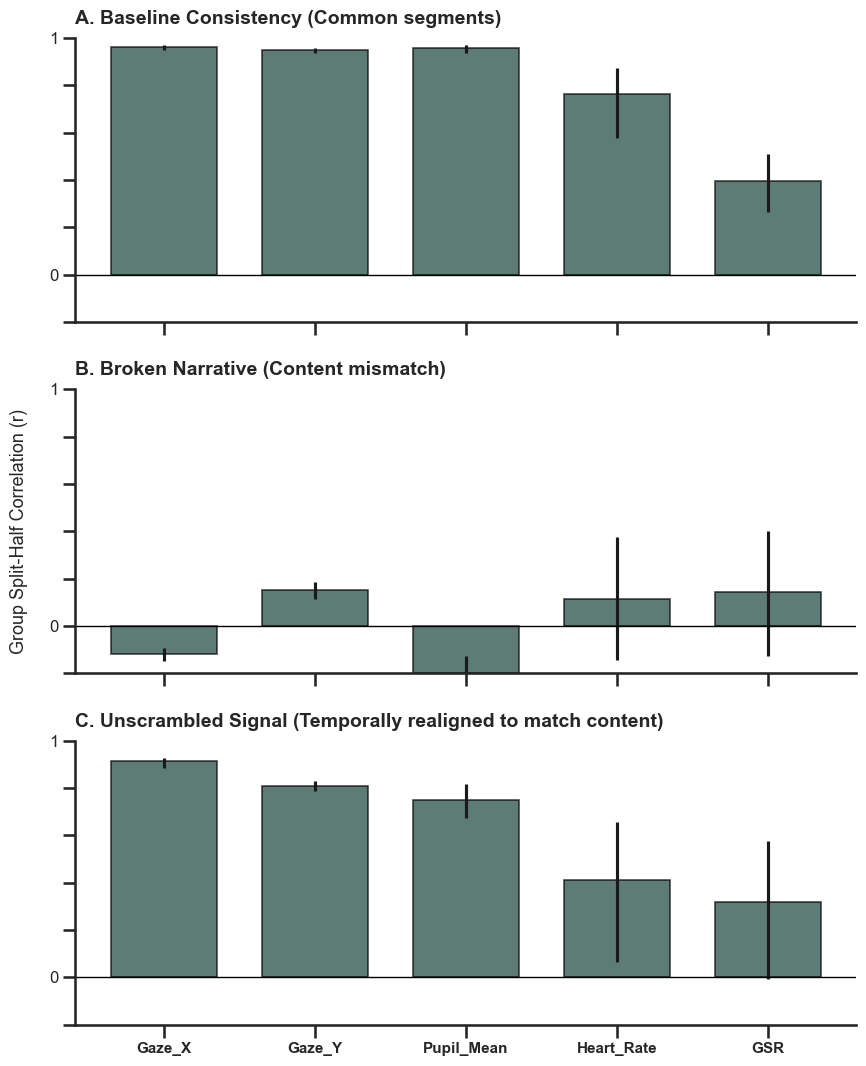

Plot saved to h2_segment_results/Master_Segment_Gradient.png


In [46]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os
import seaborn as sns
from msuthemes import theme_msu, colors, MSU_GREEN
theme_msu()

# --- CONFIG ---
RESULTS_DIR = "h2_segment_results"
CSV_PATH = os.path.join(RESULTS_DIR, "h2_segment_stats.csv")
OUTPUT_PLOT = os.path.join(RESULTS_DIR, "Master_Segment_Gradient.png")

# Load Data
df = pd.read_csv(CSV_PATH)

# Define Logic
signal_order = ['Gaze_X', 'Gaze_Y', 'Pupil_Mean', 'Heart_Rate', 'GSR']
condition_order = ["Common", "Scrambled", "Unscrambled"]
titles = [
    "A. Baseline Consistency (Common segments)",
    "B. Broken Narrative (Content mismatch)",
    "C. Unscrambled Signal (Temporally realigned to match content)"
]


# Enforce Ordering
df['Signal'] = pd.Categorical(df['Signal'], categories=signal_order, ordered=True)
df['Condition'] = pd.Categorical(df['Condition'], categories=condition_order, ordered=True)
df = df.sort_values(['Condition', 'Signal'])

# --- PLOTTING ---
sns.set(style="ticks", context="talk")
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(9, 11), sharex=True, sharey=True)

for i, cond in enumerate(condition_order):
    ax = axes[i]
    subset = df[df['Condition'] == cond]
    
    x_pos = np.arange(len(signal_order))
    
    # Bar Plot
    bars = ax.bar(x_pos, subset['Mean_r'],
                  yerr=[subset['Err_Low'], subset['Err_High']],
                  capsize=5, color=MSU_GREEN, edgecolor='black', 
                  width=0.7, alpha=0.7, linewidth=1.2)
    
    # Styling
    ax.set_title(titles[i], loc='left', fontsize=14, fontweight='bold', pad=10)
    ax.axhline(0, color='black', linewidth=1)
    #ax.grid(axis='y', linestyle='--', alpha=0.4)
    
    # --- Y-AXIS FORMATTING (Specific Request) ---
    ax.set_ylim(-0.2, 1.0)
    
    # Define the tick positions
    ticks = [-0.2, 0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
    ax.set_yticks(ticks)
    
    # Define labels: Empty strings for everything except 0 and 1
    # 0.0 is index 1, 1.0 is index 6
    labels = ["", "0", "", "", "", "", "1"]
    ax.set_yticklabels(labels, fontsize=12)

    
    sns.despine(ax=ax)

# Final formatting
axes[2].set_xticks(np.arange(len(signal_order)))
axes[2].set_xticklabels(signal_order, fontsize=11, fontweight='bold')
axes[1].set_ylabel("Group Split-Half Correlation (r)", fontsize=13, labelpad=15)

plt.tight_layout()
plt.savefig(OUTPUT_PLOT, dpi=300)
plt.show()

print(f"Plot saved to {OUTPUT_PLOT}")